In [2]:
#Importer et lister les fichiers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.stats import kurtosis

fichiers = {
    "Sain":       ("../data/normal/97.mat",  "X097_DE_time"),
    "Bague int.": ("../data/12k-DE/105.mat", "X105_DE_time"),
    "Bille":      ("../data/12k-DE/118.mat", "X118_DE_time"),
    "Bague ext.": ("../data/12k-DE/130.mat", "X130_DE_time"),
} #associe à chaque condition le chemin de son fichier et le nom de son tiroir.

signaux = {nom: np.ravel(loadmat(chemin)[tiroir])
           for nom, (chemin, tiroir) in fichiers.items()} #ouvre les quatre fichiers d’un coup et range les signaux dans un second dictionnaire.

for nom, x in signaux.items():
    print(f"{nom:12s} {len(x)} points")

def indicateurs(x):
    rms = np.sqrt(np.mean(x**2))
    pic = np.max(np.abs(x))
    return {"RMS": rms, "Pic": pic, "Crête": pic / rms,
            "Kurtosis": kurtosis(x, fisher=False)}

tableau = pd.DataFrame({nom: indicateurs(x) for nom, x in signaux.items()}).T.round(2)
tableau

Sain         243938 points
Bague int.   121265 points
Bille        122571 points
Bague ext.   121991 points


,RMS,Pic,Crête,Kurtosis
Sain,0.07,0.31,4.22,2.76
Bague int.,0.29,1.74,5.97,5.40
Bille,0.14,0.61,4.36,2.98
Bague ext.,0.67,3.63,5.42,7.65


In [3]:
def decouper(x, taille=2400): #taille=2400 pour des fenêtres de 2400 points, soit 0.2s à 12kHz. Chaque fenêtre couvre 6 tours
    n = len(x) // taille # donne le nombre de fenêtres complètes. On jette le petit reste à la fin. 
    return x[:n * taille].reshape(n, taille) #revient à couper un long ruban en morceaux égaux, puis à les empiler: chaque ligne devient une fenêtre

print(decouper(signaux["Bague int."]).shape)

(50, 2400)


In [4]:
lignes = []
for nom, x in signaux.items():
    for i, fen in enumerate(decouper(x)):
        res = indicateurs(fen)
        res["Condition"] = nom
        res["Fenêtre"] = i
        lignes.append(res)

df = pd.DataFrame(lignes)
print(df.groupby("Condition").size())
df.head()

Condition
Bague ext.     50
Bague int.     50
Bille          51
Sain          101
dtype: int64


,RMS,Pic,Crête,Kurtosis,Condition,Fenêtre
0,0.073348,0.272869,3.720207,2.859637,Sain,0
1,0.078434,0.226765,2.891156,2.863790,Sain,1
2,0.073608,0.249295,3.386784,2.794364,Sain,2
3,0.073188,0.247418,3.380577,2.935528,Sain,3
4,0.071653,0.224679,3.135669,2.833588,Sain,4


In [5]:
df.groupby("Condition")[["RMS", "Pic", "Crête", "Kurtosis"]].agg(["mean", "std"]).round(2)

RMS         Pic       Crête       Kurtosis      
            mean   std  mean   std  mean   std     mean   std
Condition                                                    
Bague ext.  0.67  0.02  3.29  0.13  4.92  0.22     7.63  0.22
Bague int.  0.29  0.00  1.49  0.11  5.13  0.40     5.40  0.32
Bille       0.14  0.00  0.50  0.05  3.61  0.31     2.97  0.12
Sain        0.07  0.00  0.24  0.02  3.22  0.27     2.76  0.12

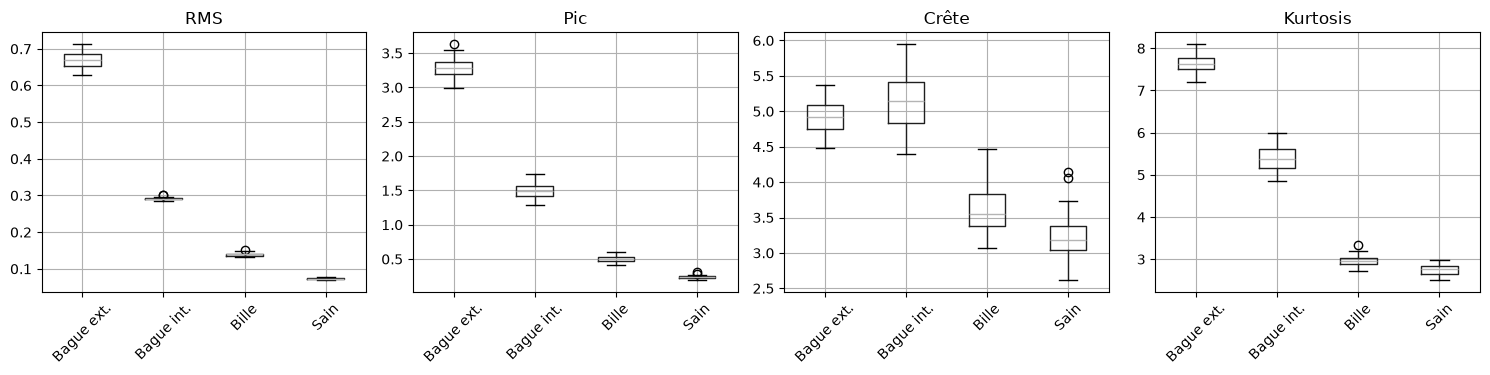

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, ind in zip(axes, ["RMS", "Pic", "Crête", "Kurtosis"]):
    df.boxplot(column=ind, by="Condition", ax=ax, rot=45)
    ax.set_title(ind)
    ax.set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()

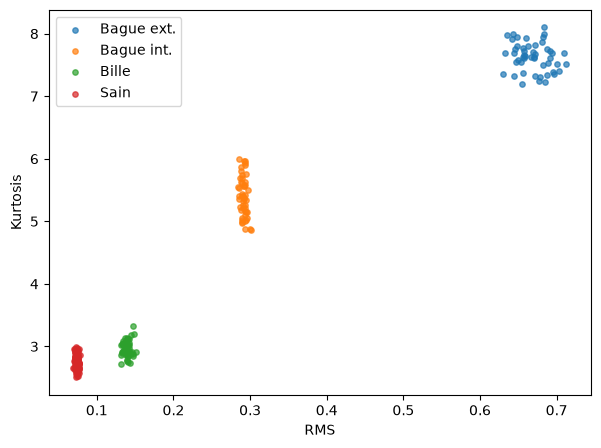

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
for nom, g in df.groupby("Condition"):
    ax.scatter(g["RMS"], g["Kurtosis"], label=nom, s=15, alpha=0.7)
ax.set_xlabel("RMS")
ax.set_ylabel("Kurtosis")
ax.legend()
plt.show()

Chaque point est une fenêtre. Ce graphique montre si deux indicateurs ensemble séparent mieux les classes qu’un seul.

- A noter que le sain a environ deux fois plus de fenêtre que les défauts. Le fichier sain contient bien deux fois plus de points (environ 244000 contre 121000). Sur les défauts la fréquence est indiquée (12kHz), on peut donc déduire que le prélèvelent a été fait sur 121000/12000 = 10s, mais nous nous disposons pas de la fréquence pour le sain. Cependant, on sait que l'arbre tourne à environs 1797 tr/min, soit ~ 30 tours par seconde. Dans le signal sain, on doit donc trouver un motif qui se répète 30 fois par seconde. 
- Sur le graphe des boxplot on observe que les indicateurs Crête et Kurtosis montrent un recouvrement entre les classes. 
- Le kurtosis ne sépare pas la bille du sain même avec la variabilité prise en compte. 
- Sur le nuage RMSxKurtosis les quatres conditions forment des groupes distincts. 